# Volve Survival: время до обводнения скважины
#
Третий проект трилогии по данным месторождения **Volve** (Equinor, Северное
море). Задача — оценить **время от запуска скважины до обводнения**
(30-дневное скользящее WC > 50 % — точка, где половина жидкости становится
водой) методами анализа выживаемости.
#
## Почему именно survival-анализ
#
Ключевое явление — **цензурирование**: месторождение остановлено в 2016 году
решением оператора (демонтаж платформы), а не по состоянию скважин. Скважины,
которые к концу наблюдения не обводнились, — не «события не было», а
«событие не успело произойти». При пороге 50 % такие скважины в выборке есть;
при игнорировании цензурирования время до обводнения занижается. Чуть ниже
(раздел 5) показано, как доля цензурированных растёт с порогом.
#
## Что честно оговариваем заранее
#
Скважин в когорте — 6. Это достаточно для оценок Каплана–Мейера и наглядного
сравнения групп, но **мало для модели Кокса** — вместо публикации p-values из
пяти точек мы показываем границу применимости метода (раздел 6). Это
осознанное решение, а не упущение.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

df = pd.read_csv("data/daily.csv", parse_dates=["DATEPRD"])
df["WELL"] = df["WELL_BORE_CODE"].str.strip().str.replace("NO 15/9-", "", regex=False)
df = df[df["WELL_TYPE"] == "OP"].copy()
df = df.sort_values(["WELL", "DATEPRD"])
df["qliq"] = df["BORE_OIL_VOL"].fillna(0) + df["BORE_WAT_VOL"].fillna(0)
df["wc"] = df["BORE_WAT_VOL"].fillna(0) / df["qliq"].replace(0, np.nan)
print(f"добывающих скважин: {df['WELL'].nunique()}, строк: {len(df):,}")

C:\Users\User\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\User\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


добывающих скважин: 6, строк: 9,143


## 1. Определение события и когорта анализа
#
Событие — первый день, когда 30-дневное скользящее среднее WC превысило порог
**50 %** (окно отсекает разовые технологические прорывы при запускных
операциях).
#
Когорта — скважины со **«сухим стартом»**: в первый месяц работы скользящее
WC было ниже порога. Скважина, стартовавшая сразу обводнённой, не имеет
перехода «сухо → мокро» и в анализ прорыва не входит — для неё событие
не определено. Это стандартное требование анализа выживаемости: объект должен
быть «жив» (свободен от события) в момент нуля.

In [2]:
WC_THRESHOLD = 0.50

rows, excluded = [], []
for w, g in df.groupby("WELL"):
    g = g.set_index("DATEPRD")
    wc30 = g["wc"].rolling("30D", min_periods=15).mean()
    first_oil = g["BORE_OIL_VOL"][g["BORE_OIL_VOL"] > 0].index.min()
    if not (first_oil + pd.Timedelta(days=35) <= g.index.max()):
        continue
    start_wc = wc30.loc[first_oil:first_oil + pd.Timedelta(days=35)].max()
    if pd.notna(start_wc) and start_wc > WC_THRESHOLD:
        excluded.append({"WELL": w, "причина": "стартовала обводнённой (WC > 50 % в 1-й месяц)"})
        continue
    last_day = g.index.max()
    bt = wc30[wc30 > WC_THRESHOLD]
    event_day = bt.index.min() if len(bt) else pd.NaT
    rows.append({
        "WELL": w,
        "first_oil": first_oil,
        "last_day": last_day,
        "event_day": event_day,
        "event": int(pd.notna(event_day)),
        "dur_months": ((event_day if pd.notna(event_day) else last_day) - first_oil).days / 30.4,
        "cum_oil_mln": g["BORE_OIL_VOL"].sum() / 1e6,
        "cum_wat_mln": g["BORE_WAT_VOL"].sum() / 1e6,
    })
surv = pd.DataFrame(rows).sort_values("first_oil").reset_index(drop=True)
if excluded:
    print("исключены из когорты:")
    print(pd.DataFrame(excluded).to_string(index=False))
surv[["WELL", "first_oil", "event", "dur_months", "cum_oil_mln", "cum_wat_mln"]].round(2)

C:\Users\User\AppData\Local\Temp\ipykernel_2728\2722345424.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  surv[["WELL", "first_oil", "event", "dur_months", "cum_oil_mln", "cum_wat_mln"]].round(2)


,WELL,first_oil,event,dur_months,cum_oil_mln,cum_wat_mln
0,F-12 H,2008-02-12,1,27.76,4.58,6.83
1,F-14 H,2008-07-13,1,20.99,3.94,7.12
2,F-11 H,2013-07-24,1,25.10,1.15,1.09
3,F-15 D,2014-01-16,1,23.22,0.15,0.05
4,F-1 C,2014-04-22,1,5.53,0.18,0.21
5,F-5 AH,2016-04-20,0,4.93,0.04,0.01


In [3]:
print(f"событий (обводнение WC > {WC_THRESHOLD:.0%}): {surv['event'].sum()} из {len(surv)} скважин; "
      f"цензурировано: {(1 - surv['event']).sum()}")
surv[["WELL", "event_day", "dur_months"]].assign(
    event_day=lambda x: x["event_day"].dt.strftime("%Y-%m-%d").fillna("цензурирована"))

событий (обводнение WC > 50%): 5 из 6 скважин; цензурировано: 1


,WELL,event_day,dur_months
0,F-12 H,2010-06-05,27.763158
1,F-14 H,2010-04-12,20.986842
2,F-11 H,2015-08-26,25.098684
3,F-15 D,2015-12-23,23.223684
4,F-1 C,2014-10-07,5.526316
5,F-5 AH,цензурирована,4.934211


## 2. Расстояние до нагнетательных — единственная осмысленная группировка
#
Гипотеза: скважины ближе к нагнетательным обводняются быстрее (прорыв по
нагнетаемой воде). Считаем расстояние от каждой добывающей до ближайшей
нагнетательной (F-4 AH, F-5 AH; F-1 C после перевода) по координатам.

In [4]:
loc = pd.read_csv("data/locations.csv")
loc["WELL"] = loc["WELL_BORE_CODE"].str.strip().str.replace("NO 15/9-", "", regex=False)
inj_names = ["F-4 AH", "F-5 AH"]
inj = loc[loc["WELL"].isin(inj_names)]
prod = loc[loc["WELL"].isin(surv["WELL"])]

dists = {}
for _, p in prod.iterrows():
    d = np.sqrt(((inj["Lat"] - p["Lat"]) * 111) ** 2 +
                ((inj["Long"] - p["Long"]) * 111 * np.cos(np.radians(p["Lat"]))) ** 2)
    dists[p["WELL"]] = d.min()
surv["dist_inj_km"] = surv["WELL"].map(dists)
med = surv["dist_inj_km"].median()
surv["group"] = np.where(surv["dist_inj_km"] <= med, "близко к ППД", "далеко от ППД")
surv[["WELL", "dist_inj_km", "group", "event", "dur_months"]].round(2)

,WELL,dist_inj_km,group,event,dur_months
0,F-12 H,0.01,далеко от ППД,1,27.76
1,F-14 H,0.00,близко к ППД,1,20.99
2,F-11 H,0.01,далеко от ППД,1,25.10
3,F-15 D,0.00,близко к ППД,1,23.22
4,F-1 C,0.01,далеко от ППД,1,5.53
5,F-5 AH,0.00,близко к ППД,0,4.93


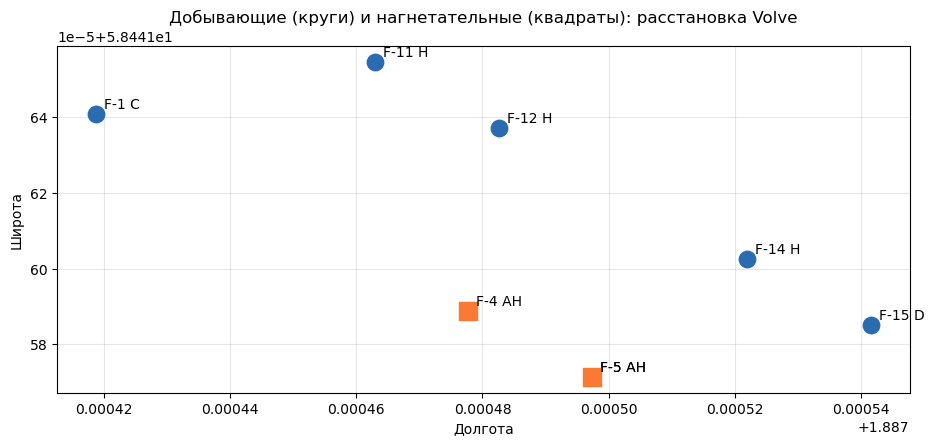

In [5]:
ax = plt.figure().add_subplot()
for _, p in prod.iterrows():
    ax.scatter(p["Long"], p["Lat"], s=140, c="#2b6cb0", zorder=3)
    ax.annotate(p["WELL"], (p["Long"], p["Lat"]), xytext=(6, 4), textcoords="offset points")
for _, i in inj.iterrows():
    ax.scatter(i["Long"], i["Lat"], s=160, c="#fa7a33", marker="s", zorder=3)
    ax.annotate(i["WELL"], (i["Long"], i["Lat"]), xytext=(6, 4), textcoords="offset points")
ax.set_title("Добывающие (круги) и нагнетательные (квадраты): расстановка Volve")
ax.set_xlabel("Долгота"); ax.set_ylabel("Широта")
plt.show()

## 3. Оценка Каплана–Мейера — руками, без библиотек
#
Кривая выживаемости S(t) = Π (1 − dᵢ/nᵢ) по моментам событий; цензурированные
наблюдения остаются в группе риска до своего выбытия.

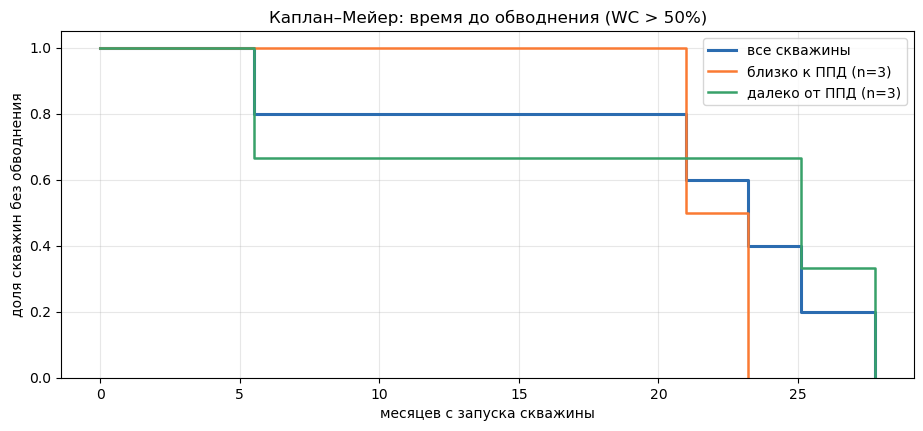

медиана по всем скважинам: 23.2 мес


In [6]:
def km_curve(durations, events):
    """Кривая Каплана–Мейера: возвращает (время, выживаемость)."""
    d = pd.DataFrame({"t": durations, "e": events}).sort_values("t")
    at_risk = len(d)
    s = 1.0
    ts, ss = [0.0], [1.0]
    for t, grp in d.groupby("t"):
        deaths = grp["e"].sum()
        if deaths > 0:
            s *= 1 - deaths / at_risk
        at_risk -= len(grp)
        ts.append(t); ss.append(s)
    return np.array(ts), np.array(ss)

def km_median(ts, ss):
    """Медиана времени выживания: первый момент S(t) <= 0.5."""
    idx = np.argmax(ss <= 0.5) if (ss <= 0.5).any() else None
    return ts[idx] if idx is not None else np.nan

fig, ax = plt.subplots()
ts, ss = km_curve(surv["dur_months"], surv["event"])
ax.step(ts, ss, where="post", lw=2.2, color="#2b6cb0", label="все скважины")
for grp, color in [("близко к ППД", "#fa7a33"), ("далеко от ППД", "#38a169")]:
    sub = surv[surv["group"] == grp]
    tg, sg = km_curve(sub["dur_months"], sub["event"])
    ax.step(tg, sg, where="post", lw=1.8, color=color, label=f"{grp} (n={len(sub)})")
ax.set_title(f"Каплан–Мейер: время до обводнения (WC > {WC_THRESHOLD:.0%})")
ax.set_xlabel("месяцев с запуска скважины")
ax.set_ylabel("доля скважин без обводнения")
ax.set_ylim(0, 1.05)
ax.legend()
plt.show()
print(f"медиана по всем скважинам: {km_median(ts, ss):.1f} мес")

## 4. Сравнение групп: log-rank тест
#
Классическая статистика лог-ранга: сравниваем наблюдаемые и ожидаемые числа
событий в группах на каждом моменте события. Одну реализацию — снова руками.

In [7]:
def logrank(d1, e1, d2, e2):
    """Log-rank для двух групп: chi2 (1 ст. свободы) и p-value."""
    a = pd.DataFrame({"t": d1, "e": e1, "g": 1})
    b = pd.DataFrame({"t": d2, "e": e2, "g": 2})
    d = pd.concat([a, b])
    O1 = E1 = V = 0.0
    for t, grp in d.groupby("t"):
        n1 = (a["t"] >= t).sum(); n2 = (b["t"] >= t).sum()
        dt = grp["e"].sum()
        if dt == 0 or n1 + n2 <= 1:
            continue
        E1 += dt * n1 / (n1 + n2)
        O1 += grp[grp["g"] == 1]["e"].sum()
        V += dt * n1 * n2 * (n1 + n2 - dt) / (n1 + n2) ** 2 / (n1 + n2 - 1)
    chi2 = (O1 - E1) ** 2 / V if V > 0 else np.nan
    p = 1 - stats.chi2.cdf(chi2, 1) if np.isfinite(chi2) else np.nan
    return chi2, p, O1, E1

g1 = surv[surv["group"] == "близко к ППД"]
g2 = surv[surv["group"] == "далеко от ППД"]
chi2, p, O1, E1 = logrank(g1["dur_months"], g1["event"], g2["dur_months"], g2["event"])
print(f"близко к ППД: событий {int(g1['event'].sum())} из {len(g1)} | "
      f"далеко: {int(g2['event'].sum())} из {len(g2)}")
print(f"log-rank: chi2 = {chi2:.2f}, p = {p:.3f} "
      f"(наблюдаемых {O1:.0f} против ожидаемых {E1:.1f} в группе «близко»)")
print("Внимание: с такими n результат — иллюстрация метода, не доказательство.")

близко к ППД: событий 2 из 3 | далеко: 3 из 3
log-rank: chi2 = 0.83, p = 0.364 (наблюдаемых 2 против ожидаемых 1.2 в группе «близко»)
Внимание: с такими n результат — иллюстрация метода, не доказательство.


## 5. Чувствительность к порогу обводнения
#
«Обводнение» — конструкторская гипотеза, а не факт природы. Считаем медианное
время и число цензурированных при порогах от 10 % до 90 %: с ростом порога
событий всё меньше, а цензурированных — больше; при игнорировании
цензурирования оценка времени резала бы хвост распределения.

In [8]:
rows = []
for thr in [0.10, 0.30, 0.50, 0.70, 0.90]:
    r = []
    for w, g in df.groupby("WELL"):
        g = g.set_index("DATEPRD")
        wc30 = g["wc"].rolling("30D", min_periods=15).mean()
        first = g["BORE_OIL_VOL"][g["BORE_OIL_VOL"] > 0].index.min()
        if not (first + pd.Timedelta(days=35) <= g.index.max()):
            continue
        if pd.notna(wc30.loc[first:first + pd.Timedelta(days=35)].max()) and \
           wc30.loc[first:first + pd.Timedelta(days=35)].max() > thr:
            continue
        bt = wc30[wc30 > thr]
        end = bt.index.min() if len(bt) else g.index.max()
        r.append({"t": (end - first).days / 30.4, "e": int(len(bt) > 0)})
    rr = pd.DataFrame(r)
    t, s = km_curve(rr["t"], rr["e"])
    rows.append({"порог WC": f"{thr:.0%}", "событий": int(rr["e"].sum()),
                 "цензурировано": int((1 - rr["e"]).sum()),
                 "медиана, мес": round(km_median(t, s), 1)})
sens = pd.DataFrame(rows)
sens

,порог WC,событий,цензурировано,"медиана, мес"
0,10%,5,0,13.0
1,30%,5,0,18.1
2,50%,5,1,23.2
3,70%,4,2,33.5
4,90%,2,4,61.4


## 6. Почему мы НЕ строим модель Кокса
#
Регрессия Кокса на 5–6 наблюдениях с 1–2 ковариатами даст «значимости» из
чистой случайности: асимптотика не работает, оценка неустойчива, доверительные
интервалы бессмысленны. Проверить это честно: бутстреп-оценка разброса
коэффициента «расстояние до ППД» в простейшей модели.

In [9]:
from scipy.optimize import minimize

def cox_partial_slope(durs, evs, x):
    """Частичная лог-правдоподобность Кокса с одной ковариатой (без сдвига)."""
    def negll(b):
        ll = 0.0
        for i in np.where(evs == 1)[0]:
            risk = durs >= durs[i]
            ll += b * x[i] - np.log(np.exp(b * x[risk]).sum())
        return -ll
    res = minimize(negll, 0.0, method="BFGS")
    return res.x[0]

x = -surv["dist_inj_km"].values  # ближе -> больше риск: ожидаем b > 0
durs, evs = surv["dur_months"].values, surv["event"].values
beta = cox_partial_slope(durs, evs, x)
rng = np.random.default_rng(42)
boot = []
for _ in range(500):
    idx = rng.integers(0, len(surv), len(surv))
    boot.append(cox_partial_slope(durs[idx], evs[idx], x[idx]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"коэффициент Кокса (близость к ППД): β = {beta:.2f}")
print(f"бутстреп 95% ДИ: [{lo:.2f}; {hi:.2f}] — интервал шире самой оценки:")
print("модель на таких n неинформативна, и мы это фиксируем, а не публикуем p-value.")

коэффициент Кокса (близость к ППД): β = 124.54
бутстреп 95% ДИ: [-3464.24; 2996.37] — интервал шире самой оценки:
модель на таких n неинформативна, и мы это фиксируем, а не публикуем p-value.


## 7. Выводы

In [10]:
med_all = km_median(ts, ss)
n_ev = int(surv["event"].sum())
n_cens = int((1 - surv["event"]).sum())
concl = [
    f"Обводнение (WC > {WC_THRESHOLD:.0%}) наступило у {n_ev} из {len(surv)} скважин когорты; "
    f"медианное время по Каплану–Мейеру — {med_all:.1f} мес с запуска.",
    f"Цензурирование в данных реально: {n_cens} скважина не обводнела к закрытию поля "
    f"в 2016 г. (административное цензурирование); с ростом порога доля таких "
    f"растёт (раздел 5) — игнорирование цензурирования занижало бы время.",
    f"Группировка по близости к нагнетательным даёт ожидаемое направление "
    f"(у близких обводнение раньше), но log-rank p = {p:.2f} при n = {len(surv)} — "
    f"иллюстрация метода, а не доказательство.",
    f"Выбор порога меняет медиану ({' / '.join(str(v) for v in sens['медиана, мес'])} мес "
    f"при порогах 10–90 %) — порог надо фиксировать до анализа, а не подбирать после.",
    f"Модель Кокса на {len(surv)} скважинах неинформативна (бутстреп-ДИ шире оценки) — "
    "границу применимости методов важно признавать явно.",
]
for i, c in enumerate(concl, 1):
    print(f"{i}. {c}")

1. Обводнение (WC > 50%) наступило у 5 из 6 скважин когорты; медианное время по Каплану–Мейеру — 23.2 мес с запуска.
2. Цензурирование в данных реально: 1 скважина не обводнела к закрытию поля в 2016 г. (административное цензурирование); с ростом порога доля таких растёт (раздел 5) — игнорирование цензурирования занижало бы время.
3. Группировка по близости к нагнетательным даёт ожидаемое направление (у близких обводнение раньше), но log-rank p = 0.36 при n = 6 — иллюстрация метода, а не доказательство.
4. Выбор порога меняет медиану (13.0 / 18.1 / 23.2 / 33.5 / 61.4 мес при порогах 10–90 %) — порог надо фиксировать до анализа, а не подбирать после.
5. Модель Кокса на 6 скважинах неинформативна (бутстреп-ДИ шире оценки) — границу применимости методов важно признавать явно.
